In [1]:
from pathlib import Path

import r5py
import accessx as acx
import osmnx as ox
import gtfs_kit as gk

## Setup

This notebook assumes you already have an environment with accessx installed.
Run the cell below once to add the other packages it uses, then restart the kernel.

r5py also needs **Java 21 or newer**. If you use conda, the conda command in the cell
below installs Java for you. With pip only, install Java yourself first
(for example on macOS: `brew install openjdk@21`).

In [ ]:
# Run once, then restart the kernel
%conda install -c conda-forge r5py -y   # conda environment: also installs Java
%pip install gtfs-kit

# pip only (no conda): use this line instead of the two above, and install Java 21+ yourself
# %pip install r5py gtfs-kit

In [2]:
epsg_mil = 32632

resolution = 9

data_path = Path("../data/case_studies/gtfs_experiments")
area_path = data_path / "area"
pois_path=data_path/"pois"
results_path = data_path / "results"

for folder in [data_path, area_path, pois_path, results_path]:
    folder.mkdir(parents=True, exist_ok=True)

#Add to the list the cities you want to analyze. Make sure to provide the correct EPSG code for each city (Projected CRS).
city_data = [
    {"name": "milan", "label": "Milan", "epsg": epsg_mil},
]

## Gtfs donwload and analysis

Download a recent gtfs for the city data. The one for Milan is taken from https://mobilitydatabase.org/feeds/gtfs/mdb-2666

In [5]:
GTFS_PATH = "../data/milan_gtfs_experiments/mdb-2666-202610300145.zip"
gk.list_feed(GTFS_PATH)

,file_name,file_size
0,agency.txt,188
1,calendar.txt,109
2,calendar_dates.txt,263307
3,feed_info.txt,209
4,routes.txt,15121
5,shapes.txt,16967543
6,stops.txt,548684
7,stop_times.txt,307569442
8,transfers.txt,261
9,trips.txt,23305333


In [8]:
feed=gk.read_feed(GTFS_PATH)
feed.describe()

,indicator,value
0,agencies,[ATM]
1,timezone,Europe/Rome
2,start_date,20261026
3,end_date,20261130
4,num_routes,170
5,num_trips,124557
6,num_stops,4919
7,num_shapes,791
8,sample_date,20261029
9,num_routes_active_on_sample_date,162


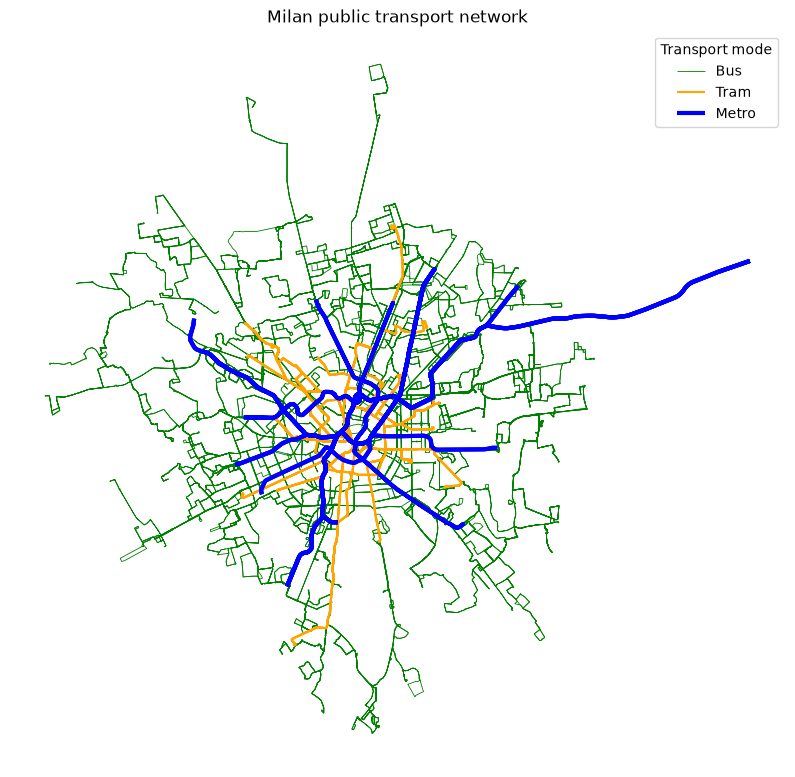

In [13]:
import matplotlib.pyplot as plt

# Get routes as a GeoDataFrame
routes = feed.get_routes(as_gdf=True)

# Fixed colours for each transport mode
modes = {
    3: ("Bus", "green", 0.6),
    0: ("Tram", "orange", 1.5),
    1: ("Metro", "blue", 3),
}

# Plot the network
fig, ax = plt.subplots(figsize=(10, 10))

for route_type, (label, color, width) in modes.items():
    routes[routes["route_type"] == route_type].plot(
        ax=ax,
        color=color,
        linewidth=width,
        label=label
    )

ax.legend(title="Transport mode")
ax.set_title("Milan public transport network")
ax.set_axis_off()

plt.show()


## Load AOI and make Hex Grid

In [3]:
aois = {
    "milan": ox.geocode_to_gdf("Milan, Italy"),
}

for city in city_data:
    acx.save_gdf(aois[city["name"]], area_path / f"aoi_{city['name']}.geojson")

# Uncomment to read saved AOIs instead of geocoding.
# aois = {
#     city["name"]: acx.read_gdf(area_path / f"aoi_{city['name']}.geojson")
#     for city in city_data
# }

## Collect POIs

In [ ]:
poi_groups = {
    "healthcare": {
        "amenity": ["pharmacy", "clinic", "doctors", "dentist", "hospital"],
        "healthcare": True,
    },
}


pois = {}
poi_reports = {}

for city in city_data:
    name = city["name"]
    pois[name], poi_reports[name] = acx.get_pois_osm(
        aois[name],
        poi_groups=poi_groups,
        max_retries=4,
        show_progress=True,
        return_report=True,
        columns="minimal",
    )
    # A feature can match more than one OSM query inside the same custom group.
    # Keep one opportunity per category and OSM identity before calculating scores.
    pois[name] = pois[name].drop_duplicates(
        subset=["category", "osm_type", "osmid"]
    ).reset_index(drop=True)
    pois[name]["id"] = range(len(pois[name]))

    acx.save_gdf(pois[name], pois_path / f"pois_{name}.geojson")

# Uncomment to read saved POIs instead of querying OSM again.
# pois = {
#     city["name"]: acx.read_gdf(pois_path / f"pois_{city['name']}.geojson")
#     for city in city_data
# }

## Cumulative accessibility with r5py

Check if there are stops with no name

In [17]:
missing = feed.stops[feed.stops["stop_name"].isna()]
print(len(missing), missing["stop_id"].tolist())


0 []


Check if calendar.txt is empty

In [ ]:
print(feed.calendar)              

None


In [19]:
# r5py is stricter than gtfs_kit and refuses this feed as it is, for two reasons:
# 1. calendar.txt is in the zip but empty -> gtfs_kit already stores it as None, so it is not written back
# 2. one stop (17369) has no stop_name -> use its stop_id as name
feed_r5 = feed.copy()

#Uncomment if there are stops with missing names, otherwise r5py will refuse the feed
# feed_r5.stops["stop_name"] = feed_r5.stops["stop_name"].fillna(feed_r5.stops["stop_id"])

GTFS_R5_PATH = "../data/milan_gtfs_experiments/mdb-2666-202610300145_r5.zip"
feed_r5.to_file(GTFS_R5_PATH)  # to_file writes only the tables that aren't None, so the new zip has NO calendar.txt

Load transport network 

In [20]:
# Transport network: street network from OpenStreetMap + timetables from GTFS
# Building it takes ~5 minutes the first time
transport_network = r5py.TransportNetwork(
    "../data/milan_gtfs_experiments/milan.osm.pbf",
    [GTFS_R5_PATH],
)

The centre of each hexagon are the origins of the accessibility calculations. Destinations are the points of interest

In [23]:
import geopandas as gpd

#Origins
hexes_milan = gpd.read_file(area_path / "hexes_milan.geojson")
#r5py needs an "id" column
hexes_renamed = hexes_milan.rename(columns={"hex_id": "id"})
origins = hexes_renamed
origins.geometry = origins.to_crs(epsg_mil).centroid.to_crs("EPSG:4326")  # centroids computed in metres (UTM)

# Destination
pois_all=gpd.read_file(pois_path / "pois_milan.geojson")

Compute travel times within max_time using r5py

In [44]:
import datetime
travel_times = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins,
    destinations=pois_all,
    departure=datetime.datetime(2026, 11, 18, 8, 30),  # Wednesday 18 Nov, 8:30
    transport_modes=[
        r5py.TransportMode.TRANSIT,
        r5py.TransportMode.WALK,
    ],
    max_time=datetime.timedelta(minutes=15),  # max_time must be a timedelta, not a number
    snap_to_network=True,
)

# r5py still returns one row per origin: origins over the limit have travel_time = NaN, so drop them
travel_times = travel_times.dropna(subset=["travel_time"])
travel_times

/Users/MartaMagnani/anaconda3/envs/transit/lib/python3.12/site-packages/r5py/r5/base_travel_time_matrix.py:227: RuntimeWarning: Some destination points could not be snapped to the street network
  warnings.warn(


,from_id,to_id,travel_time
19299,891f995768fffff,508,13.0
20933,891f9957683ffff,508,12.0
21750,891f9957687ffff,508,10.0
21757,891f9957687ffff,515,12.0
21886,891f9957687ffff,644,14.0
...,...,...,...
1554542,891f99cc58bffff,608,12.0
1555359,891f99cc58fffff,608,8.0
1555446,891f99cc58fffff,695,12.0
1555447,891f99cc58fffff,696,12.0


In [46]:
travel_times["count"] = travel_times.groupby("from_id")["from_id"].transform("size")
#size counts the number of rows in each group
#transform ensures that the result has the same length and index as the original DataFrame
travel_times_counts = (
    travel_times
    .drop_duplicates(subset="from_id", keep="first")
    .drop(columns="to_id")
    .drop(columns="travel_time")
)
travel_times_counts

,from_id,count
19299,891f995768fffff,1
20933,891f9957683ffff,1
21750,891f9957687ffff,4
23384,891f9957697ffff,4
24201,891f995744bffff,3
...,...,...
1552471,891f99ce36fffff,2
1553486,891f99ce367ffff,1
1554303,891f99cc58bffff,3
1555359,891f99cc58fffff,3


Static map of hexagons coloured by count of accessible POis. Pois are also plotted on top

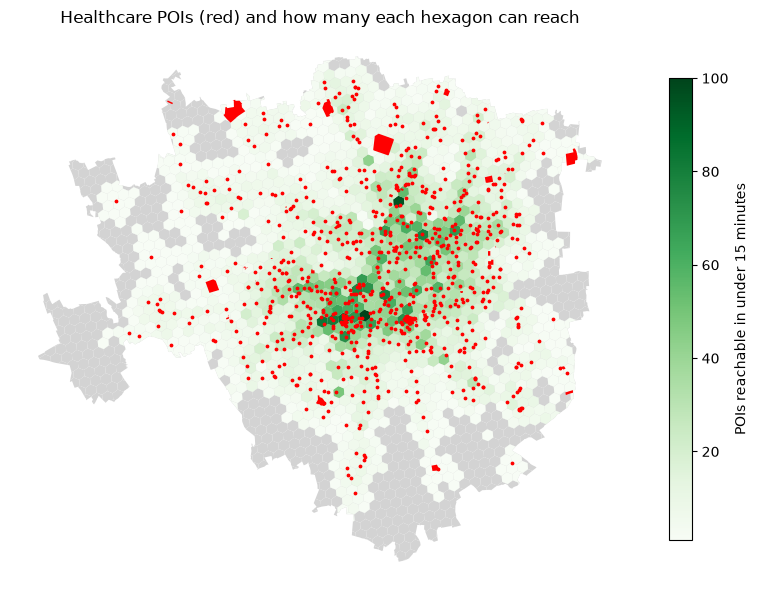

In [47]:
# Static map: hexagons coloured by count, with the POIs on top
# travel_times_counts is a plain table (from_id, count) with no geometry,
# so join it to the hexagon shapes first (hex_id in hexes_milan = from_id in the table)
hexes_counts = hexes_milan.merge(travel_times_counts, left_on="hex_id", right_on="from_id")

# Hexagons that reach no POI are not in travel_times_counts, so all hexagons are drawn in grey first
ax = hexes_milan.plot(color="lightgrey", figsize=(10, 10))
hexes_counts.plot(ax=ax, column="count", cmap="Greens", legend=True,
                  legend_kwds={"label": "POIs reachable in under 15 minutes", "shrink": 0.6})
pois_all.plot(ax=ax, color="red", markersize=3)
ax.set_title("Healthcare POIs (red) and how many each hexagon can reach")
ax.set_axis_off()

Dynamic map

In [48]:
travel_times_counts = hexes_milan.merge(travel_times_counts, left_on="hex_id", right_on="from_id")
travel_times_counts.explore("count", cmap="Greens")